#### ▶ 인공 신경망
- nn모듈 : 신경망을 구축하고 학습시키는데 필요한 모든 구성요소를 제공하는 핵심 모듈
- 주요 역할및 구성 요소
    1. 인공 신경망 레이어(Layer) : 입력데이터를 변환하는 다양한 층을 제공
        - 선형 레이어(nn.Linear) : 완전연결층
        - 합성곱 레이어(nn.Conv2d) : 이미지 처리에 쓰이는 CNN레이어
        - 순환 레이어(nn.LTSM, nn.GRU) : 텍스트, 시계열 처리에 쓰는 RNN 레이어
    2. 활성화 함수(Activation Functions) : 비선형성을 추가하여 모델이 복잡한 패턴을 학습 할 수 있도록 해준다.
        - nn.ReLU(), nn.Sigmoid(), nn.Softmax() 등
    3. 손실 함수(Loss Functions) : 모델의 예측값과 실제 값의 오차를 계산
        - nn.MESLoss(), nn.CrossEntropyLoss() 등
    4. 컨테이너 : 여러 레이어를 묶어서 하나의 모델로 구조화
        - nn.Module : 모든 신경망 모델의 기본 클래스
        - 자신이 만드는 모든 커스텀 모델은 nn.Module을 상속받아 정의하여 사용
        - nn.Sequential : 레이어를 순차적으로 연결해 주는 간단한 래퍼임.

In [1]:
import torch
from torch import nn
from torchviz import make_dot

Linear(in_features=1, out_features=1, bias=True)

w =  Parameter containing:
tensor([[0.3856]], requires_grad=True)
b =  Parameter containing:
tensor([0.9492], requires_grad=True)

결과 : tensor([1.3348], grad_fn=<UnsafeViewBackward0>)


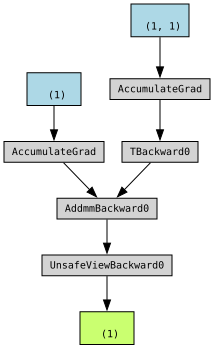

In [2]:
x = torch.tensor([1.])

model = nn.Linear(1, 1)
print(model)
print()

print('w = ', model.weight)
print('b = ', model.bias)
print()

y = model(x)
print('결과 :', y)

# y2 = x @ model.weight  + model.bias
# print('y2 :', y2)

make_dot(y)

fc1의 w = Parameter containing:
tensor([[ 0.1054],
        [-0.3255],
        [-0.5498]], requires_grad=True)
fc1의 가중치 행렬 = torch.Size([3, 1])
fc1의 b = Parameter containing:
tensor([ 0.3649, -0.7089, -0.2915], requires_grad=True)
fc1의 bias size = torch.Size([3])
------------------------------
fc2의 w = Parameter containing:
tensor([[-0.3957, -0.4449,  0.2557]], requires_grad=True)
fc2의 b = Parameter containing:
tensor([0.4295], requires_grad=True)
------------------------------
tensor([ 0.4703, -1.0344, -0.8413], grad_fn=<UnsafeViewBackward0>)
tensor([0.4885], grad_fn=<UnsafeViewBackward0>)
tensor([0.4885], grad_fn=<AddBackward0>)


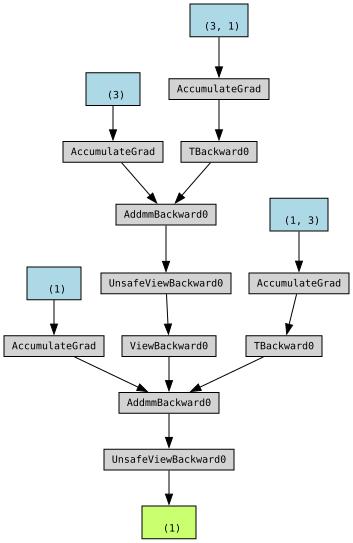

In [11]:
fc1 = nn.Linear(1, 3)
fc2 = nn.Linear(3, 1)

print('fc1의 w =', fc1.weight)
print('fc1의 가중치 행렬 =', fc1.weight.shape)
# W.shape = (out_features, in_features)

print('fc1의 b =', fc1.bias)
print('fc1의 bias size =', fc1.bias.shape)
print('-' * 30)

print('fc2의 w =', fc2.weight)
print('fc2의 b =', fc2.bias)
print('-' * 30)

x = torch.tensor([1.])
x = fc1(x)
print(x)
y = fc2(x)
print(y)

x = torch.tensor([1.])
y2 = (x @ fc1.weight.T + fc1.bias) @ fc2.weight.T + fc2.bias
print(y2)

make_dot(y)

Feature과 Channel의 차이
| 구분 | Feature | Channel |
| --- | --- | --- |
| 의미 | 데이터가 가진 특성 또는 변수 | 데이터의 독립적인 데이터 경로 또는 구성요소 |
| 예시 | 나이, 키, 몸무게 | RGB 이미지의 R,G,B |
| 주로 사용하는 곳 | 일반적인 데이터, 머신러닝, 완전연결층 | 이지미처리, CNN, 신호처리 |

tensor([-1.3679, -1.6627])
tensor([ 1.0987,  1.7876, -1.0269], grad_fn=<UnsafeViewBackward0>)


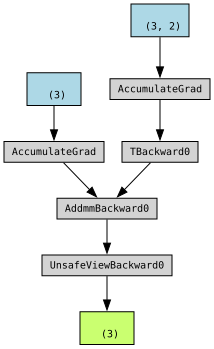

In [ ]:
model = nn.Linear(2, 3)
# 2개의 채널(or Feature)를 가진 데이터에 대해 3개의 채널(or Feature)을 가지는 데이터로 변환하는것
x = torch.randn(2)
print(x)
print(model(x))

make_dot(model(x))

tensor([[ 1.8591,  0.0351],
        [-0.7896,  0.0748],
        [ 0.4586,  0.2572],
        [-1.1082, -0.5807],
        [ 1.3596,  0.6408]])
torch.Size([5, 3])
torch.Size([4, 5, 3])
torch.Size([2, 3, 6, 5, 3, 3])


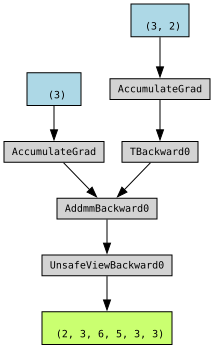

In [17]:
model = nn.Linear(2, 3)

x = torch.randn(5, 2) # 2개의 특징(몸무게, 키)을 가지는 데이터(사람) 5개(명)

print(x)
model_x = model(x)
print(model_x.shape)

x = torch.randn(4,5,2)
print(model(x).shape)

x = torch.randn(2,3,6,5,3,2)
print(model(x).shape)

make_dot(model(x))

In [18]:
fc1 = nn.Linear(1,3)
fc2 = nn.Linear(3,1)

x = torch.tensor([1.])
x = fc1(x)
y = fc2(x)

model = nn.Sequential(fc1, fc2)
x = torch.tensor([1.])
print(model(x))

tensor([0.3815], grad_fn=<UnsafeViewBackward0>)


In [19]:
model = nn.Sequential(nn.Linear(2, 5),
                      nn.Linear(5, 10),
                      nn.Linear(10, 3))

x = torch.randn(5, 2)
print(model(x))

tensor([[-0.1231, -0.1208,  0.2421],
        [ 0.1255, -0.1312, -0.1956],
        [-0.0475, -0.0542,  0.3419],
        [-0.0204, -0.0109,  0.4425],
        [-0.1522, -0.0214,  0.6212]], grad_fn=<AddmmBackward0>)
